#  EDA Report

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data.csv", encoding="cp1252")

print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset shape: (541909, 8)
Number of rows: 541909
Number of columns: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## Data quality assessment
This section identifies missing values, duplicate records, invalid values, and data-type issues without fixing them.

In [2]:
missing_count = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_report = missing_report.sort_values(
    "Missing Percentage", ascending=False
)

display(missing_report)

,Missing Count,Missing Percentage
CustomerID,135080,24.93
Description,1454,0.27
StockCode,0,0.00
InvoiceNo,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


## Duplicate records

In [3]:
duplicate_count = df.duplicated().sum()
duplicate_percentage = df.duplicated().mean() * 100

print("Duplicate rows:", duplicate_count)
print("Duplicate percentage:", round(duplicate_percentage, 2), "%")

Duplicate rows: 5268
Duplicate percentage: 0.97 %


## Potential invalid values

In [4]:
invalid_report = {
    "Negative Quantity": (df["Quantity"] < 0).sum(),
    "Zero Quantity": (df["Quantity"] == 0).sum(),
    "Negative UnitPrice": (df["UnitPrice"] < 0).sum(),
    "Zero UnitPrice": (df["UnitPrice"] == 0).sum(),
    "Missing InvoiceNo": df["InvoiceNo"].isna().sum(),
    "Missing StockCode": df["StockCode"].isna().sum()
}

for issue, count in invalid_report.items():
    print(f"{issue}: {count}")

Negative Quantity: 10624
Zero Quantity: 0
Negative UnitPrice: 2
Zero UnitPrice: 2515
Missing InvoiceNo: 0
Missing StockCode: 0


## Data-type assessment

In [5]:
dtype_report = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Unique Values": df.nunique(dropna=True),
    "Missing Values": df.isnull().sum()
})

display(dtype_report)

,Data Type,Unique Values,Missing Values
InvoiceNo,str,25900,0
StockCode,str,4070,0
Description,str,4223,1454
Quantity,int64,722,0
InvoiceDate,str,23260,0
UnitPrice,float64,1630,0
CustomerID,float64,4372,135080
Country,str,38,0


In [6]:
parsed_dates = pd.to_datetime(df["InvoiceDate"], errors="coerce")

print("Current InvoiceDate dtype:", df["InvoiceDate"].dtype)
print("Unparseable date values:", parsed_dates.isna().sum())

Current InvoiceDate dtype: str
Unparseable date values: 0


## Statistical findings
This section summarizes the central tendency, spread, distribution, and potential outliers in important numerical features.

In [7]:
numeric_columns = ["Quantity", "UnitPrice"]

statistics_report = df[numeric_columns].describe().T

statistics_report["Median"] = df[numeric_columns].median()
statistics_report["Variance"] = df[numeric_columns].var()
statistics_report["Skewness"] = df[numeric_columns].skew()
statistics_report["Kurtosis"] = df[numeric_columns].kurt()

display(statistics_report.round(3))

,count,mean,std,min,25%,50%,75%,max,Median,Variance,Skewness,Kurtosis
Quantity,541909.0,9.552,218.081,-80995.00,1.00,3.00,10.00,80995.0,3.00,47559.391,-0.264,119769.160
UnitPrice,541909.0,4.611,96.760,-11062.06,1.25,2.08,4.13,38970.0,2.08,9362.469,186.507,59005.719


## Distribution plots

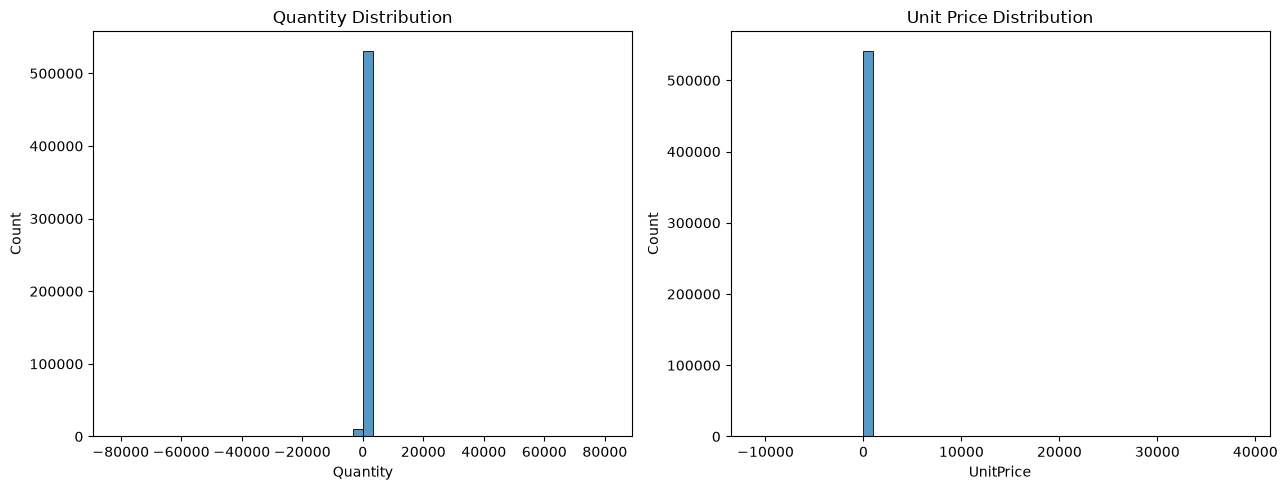

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(data=df, x="Quantity", bins=50, ax=axes[0])
axes[0].set_title("Quantity Distribution")

sns.histplot(data=df, x="UnitPrice", bins=50, ax=axes[1])
axes[1].set_title("Unit Price Distribution")

plt.tight_layout()
plt.show()

## Potential outliers

In [9]:
outlier_summary = []

for column in numeric_columns:
    series = df[column].dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    flagged = ((series < lower) | (series > upper)).sum()

    outlier_summary.append({
        "Feature": column,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Potential Outliers": int(flagged),
        "Percentage": round(flagged / len(series) * 100, 2)
        if len(series) else np.nan
    })

outlier_report = pd.DataFrame(outlier_summary)
display(outlier_report.round(3))

,Feature,Lower Bound,Upper Bound,Potential Outliers,Percentage
0,Quantity,-12.50,23.50,58619,10.82
1,UnitPrice,-3.07,8.45,39627,7.31


## Relationship findings

,Quantity,UnitPrice
Quantity,1.000,-0.001
UnitPrice,-0.001,1.000


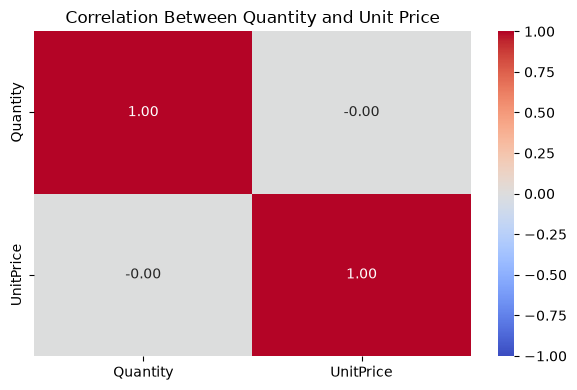

In [10]:
correlation_data = df[["Quantity", "UnitPrice"]].dropna()
correlation_matrix = correlation_data.corr()

display(correlation_matrix.round(3))

plt.figure(figsize=(6, 4))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Between Quantity and Unit Price")
plt.tight_layout()
plt.show()

### Feature relationship examples

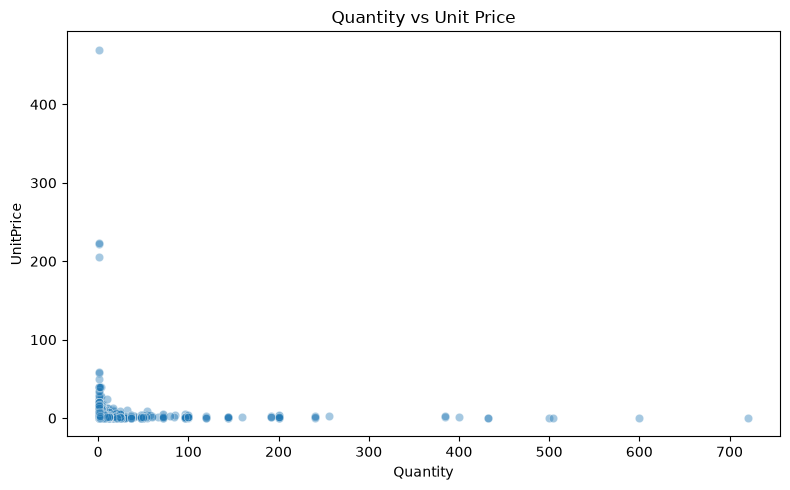

In [11]:
sample_df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
][["Quantity", "UnitPrice"]].dropna()

sample_df = sample_df.sample(
    n=min(3000, len(sample_df)),
    random_state=42
)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=sample_df,
    x="Quantity",
    y="UnitPrice",
    alpha=0.4
)

plt.title("Quantity vs Unit Price")
plt.tight_layout()
plt.show()

## Categorical patterns

Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64

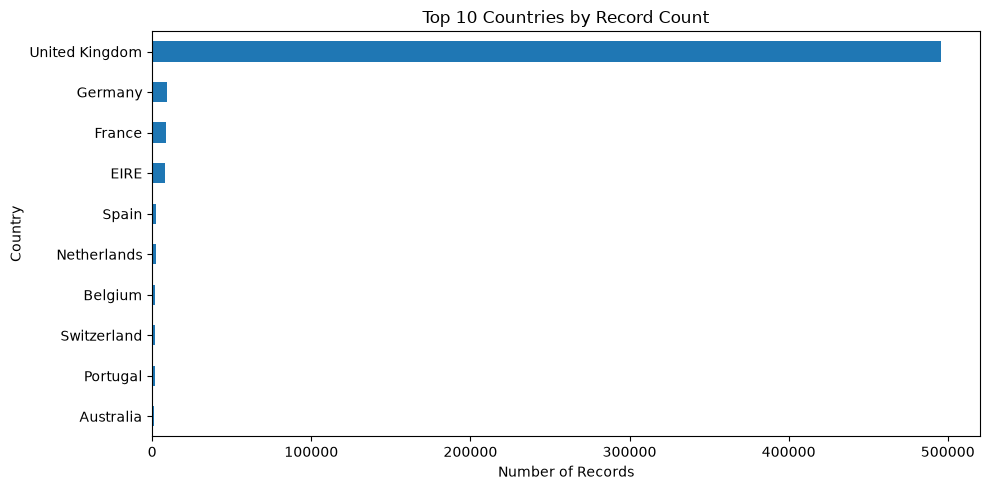

In [12]:
top_countries = df["Country"].value_counts().head(10)

display(top_countries)

plt.figure(figsize=(10, 5))
top_countries.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Record Count")
plt.xlabel("Number of Records")
plt.ylabel("Country")
plt.tight_layout()
plt.show()